# Анализ влияния различных факторов на активность подписчиков Ирины Горбачевой в Instagram

<b>Автор:</b> Луцкова Екатерина

<b>Дата:</b> 06.10.2026

<b>Цель проекта:</b> оценить влияние различных факторов на количество реакций к постам актрисы Ирины Горбачевой в социальной сети Instagram.

<b>Описание данных</b>

В проекте использован датасет с информацией об активности подписчиков Ирины Горбачевой. Рассматриваемый период - с 1 апреля по 3 октября 2026 года. 

Описание столбцов:

* `post_date` - дата поста
* `likes` - количество лайков к посту
* `comments` - количество комментариев к посту
* `shares` - количество репостов 
* `is_collab` - является ли пост совместным с другим автором
* `tag` - тема поста
* `is_series` - наличие "серии" фотографий в посте

<b>Содержание проекта:</b>
1. [Загрузка данных и знакомство с ними](#Загрузка-данных-и-знакомство-с-ними)
2. [Анализ поведения подписчиков и поиск закономерностей](#Анализ-поведения-подписчиков-и-поиск-закономерностей)
3. [Итоговые выводы](#Итоговые-выводы)

## Загрузка данных и знакомство с ними

In [1]:
# Подключаем библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# загружаем данные
insta_data = pd.read_csv("C:/Users/eklut/OneDrive/Рабочий стол/Анализ страницы Горбачевой/data.csv")

In [3]:
# выводим информацию о данных, оцениваем корректность
insta_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112 entries, 0 to 111
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   post_date  112 non-null    object
 1   likes      112 non-null    int64 
 2   comments   112 non-null    int64 
 3   shares     112 non-null    int64 
 4   is_collab  112 non-null    int64 
 5   tag        112 non-null    object
 6   is_series  112 non-null    int64 
dtypes: int64(5), object(2)
memory usage: 6.2+ KB


In [4]:
insta_data.head()

,post_date,likes,comments,shares,is_collab,tag,is_series
0,2026-10-03,1865,11,7,1,fashion,1
1,2026-10-02,2832,16,25,1,cosmetics,0
2,2026-10-02,1218,27,50,1,fashion,0
3,2026-09-30,2202,35,8,1,fashion,0
4,2026-09-26,13500,80,89,1,sport,1


In [5]:
# приводим к оптимальному типу данных
insta_data['post_date'] = insta_data['post_date'].astype('datetime64[ns]')

In [6]:
# создаем столбец, хранящий день недели, в который сделана публикация
insta_data['dow'] = insta_data['post_date'].dt.weekday +1

In [7]:
# выводим получившуюся таблицу
insta_data.head()

,post_date,likes,comments,shares,is_collab,tag,is_series,dow
0,2026-10-03,1865,11,7,1,fashion,1,6
1,2026-10-02,2832,16,25,1,cosmetics,0,5
2,2026-10-02,1218,27,50,1,fashion,0,5
3,2026-09-30,2202,35,8,1,fashion,0,3
4,2026-09-26,13500,80,89,1,sport,1,6


## Анализ поведения подписчиков и поиск закономерностей

Попробуем выяснить, как различные факторы влияют на количество лайков, комментариев и репостов под публикациями Ирины.

<b>Анализ влияния дня недели</b>

In [8]:
# исследуем влияние дня недели на среднее количество лайков
grouped_dow_likes = insta_data.groupby('dow')['likes'].mean().round(0).astype(int)
grouped_dow_likes

dow
1    84739
2    53988
3    42312
4    95045
5    63696
6    46036
7    61518
Name: likes, dtype: int32

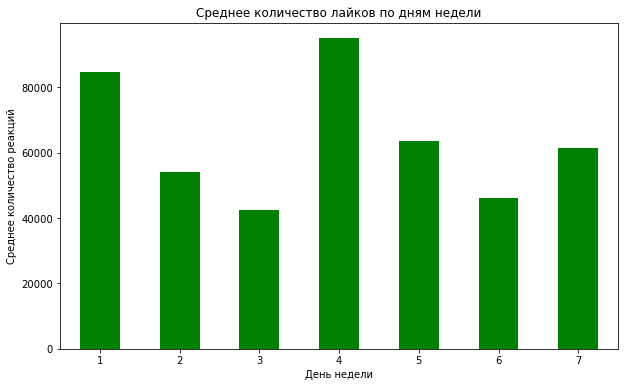

In [9]:
# визуализируем результаты
grouped_dow_likes.plot(kind='bar',
                title='Среднее количество лайков по дням недели',
                xlabel='День недели',
                ylabel='Среднее количество реакций',
                rot=0,
                color='green',       
                figsize=(10, 6))

plt.show()

In [10]:
# исследуем влияние дня недели на среднее количество комментариев
grouped_dow_comments = insta_data.groupby('dow')['comments'].mean().round(0).astype(int)
grouped_dow_comments

dow
1    1053
2     711
3     447
4    1590
5     758
6     468
7     603
Name: comments, dtype: int32

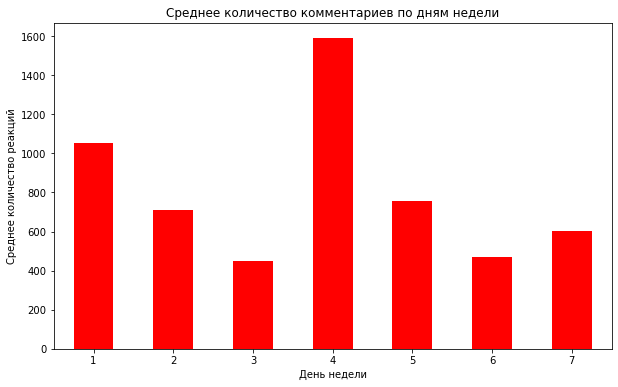

In [11]:
# визуализируем результаты
grouped_dow_comments.plot(kind='bar',
                title='Среднее количество комментариев по дням недели',
                xlabel='День недели',
                ylabel='Среднее количество реакций',
                rot=0,
                color='red',          
                figsize=(10, 6))

plt.show()

In [12]:
# исследуем влияние дня недели на среднее количество репостов
grouped_dow_shares = insta_data.groupby('dow')['shares'].mean().round(0).astype(int)
grouped_dow_shares

dow
1     5564
2     6090
3     1300
4    14220
5     6265
6     8350
7     3734
Name: shares, dtype: int32

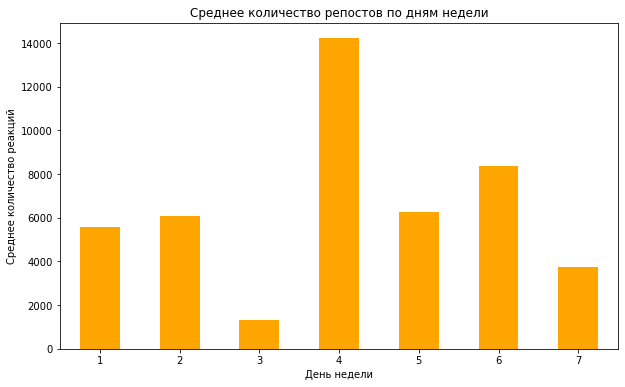

In [13]:
# визуализируем результаты
grouped_dow_shares.plot(kind='bar',
                title='Среднее количество репостов по дням недели',
                xlabel='День недели',
                ylabel='Среднее количество реакций',
                rot=0,
                color='orange',          
                figsize=(10, 6))

plt.show()

Видим, что наиболее активными днями по части лайков и комментариев являются понедельник и четверг. 
Четверг также лидирует по количеству репостов. На втором месте по репостам - суббота.
По всем трем видам реакций самый "вялый" день - среда.

<b>Анализ влияния разницы в днях между публикациями</b>

In [14]:
# отсортируем данные по дате поста, чтобы избежать отрицательных значений при расчете разницы в днях
insta_data = insta_data.sort_values('post_date')

# создаем переменную с разницей между датами публикации
insta_data['days_diff'] = (insta_data['post_date'] - insta_data['post_date'].shift(1)).dt.days

# запишем функцию, которая присвоит посту категорию в зависимости от разницы в днях
def categorize_diff(diff):
    if diff == 0:
        return '0 дней'
    if 1 <= diff <= 2:
        return 'От 1 до 2 дней'
    if diff >= 3:
        return 'Более 3 дней'

insta_data['days_category'] = insta_data['days_diff'].apply(categorize_diff)

In [15]:
# исследуем влияние разницы в днях между постами на среднее количество реакций
days_category_mean = insta_data.groupby('days_category').agg({'likes':'mean','comments':'mean','shares':'mean'}).round(0).astype(int)
days_category_mean

,likes,comments,shares
days_category,,,
0 дней,36920,623,5380
Более 3 дней,39203,593,875
От 1 до 2 дней,71246,859,8179


Посты, опубликованные в тот же день вслед за предыдущими, получают в среднем наполовину МЕНЬШЕ лайков, чем посты, опубликованные с разницей в 1-2 дня. Опубликованные с разницей в 3 и более дней - получают в среднем лишь на 3000 лайков больше.

Больше всего комментариев и репостов также делают к постам, опубликованным с разницей 1-2 дня. Меньше всего - если пост опубликован с разницей в 3 и более дней. 

<b>Анализ влияния темы публикации</b>

In [16]:
# исследуем влияние темы публикации на среднее количество лайков
grouped_tag_likes = insta_data.groupby('tag')['likes'].mean().sort_values(ascending = False).round(0).astype(int)
grouped_tag_likes

tag
interview      148648
family         112300
life            96155
health          55812
dancing         53276
sport           50182
house goods     42707
fashion         30003
event           18813
cosmetics        8958
cinema           6022
Name: likes, dtype: int32

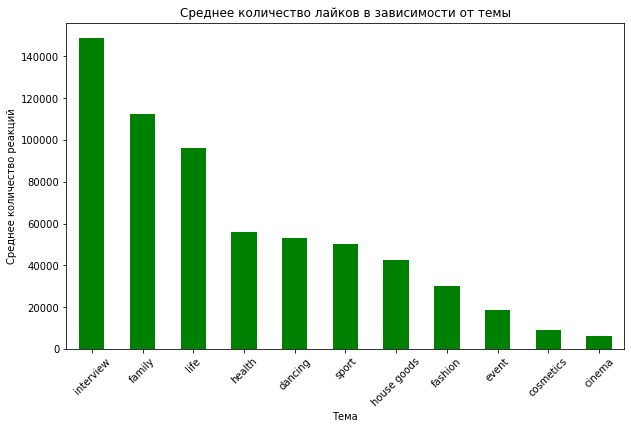

In [17]:
# визуализируем результаты
grouped_tag_likes.plot(kind='bar',
                title='Среднее количество лайков в зависимости от темы',
                xlabel='Тема',
                ylabel='Среднее количество реакций',
                rot=45,
                color='green',       
                figsize=(10, 6))

plt.show()

In [18]:
# исследуем влияние темы публикации на среднее количество комментариев
grouped_tag_comments = insta_data.groupby('tag')['comments'].mean().sort_values(ascending = False).round(0).astype(int)
grouped_tag_comments

tag
interview      1573
life           1190
family          977
sport           816
fashion         808
health          551
dancing         490
house goods     340
event           117
cosmetics        53
cinema           20
Name: comments, dtype: int32

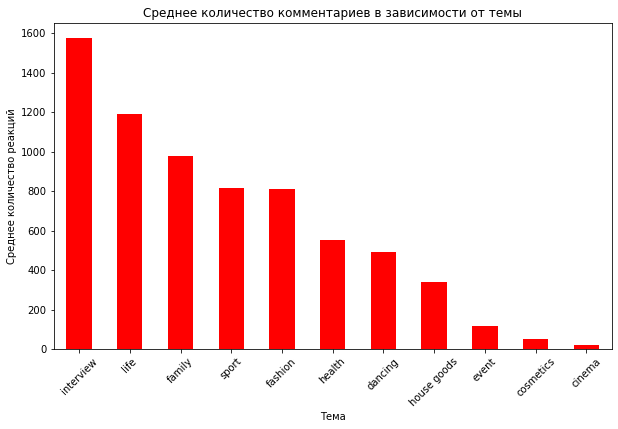

In [19]:
# визуализируем результаты
grouped_tag_comments.plot(kind='bar',
                title='Среднее количество комментариев в зависимости от темы',
                xlabel='Тема',
                ylabel='Среднее количество реакций',
                rot=45,
                color='red',          
                figsize=(10, 6))

plt.show()

In [20]:
# исследуем влияние темы публикации на среднее количество репостов
grouped_tag_shares = insta_data.groupby('tag')['shares'].mean().sort_values(ascending = False).round(0).astype(int)
grouped_tag_shares

tag
interview      23455
life           12303
sport           6707
house goods     3885
dancing         2578
health          2230
family          1383
cinema          1213
fashion          944
event            128
cosmetics         60
Name: shares, dtype: int32

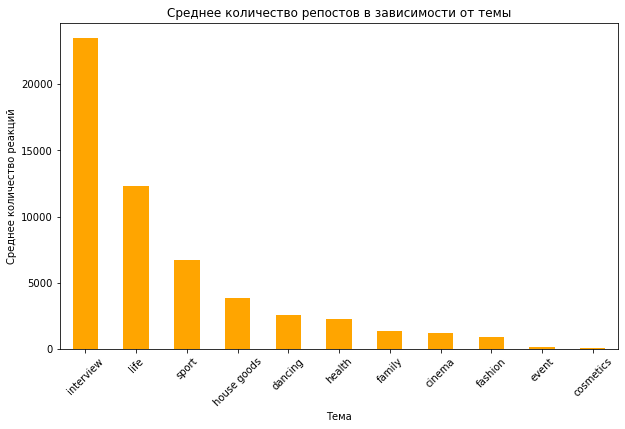

In [21]:
# визуализируем результаты
grouped_tag_shares.plot(kind='bar',
                title='Среднее количество репостов в зависимости от темы',
                xlabel='Тема',
                ylabel='Среднее количество реакций',
                rot=45,
                color='orange',          
                figsize=(10, 6))

plt.show()

Абсолютным лидером по лайкам, комментариям и репостам являются посты с кусочками интервью Ирины. 

На втором месте по лайкам - тема семьи. Ирина выкладывала фотосессию со своей бабушкой, и все эти посты имели большой успех у аудитории.

Третье место по лайкам - лайф-контент (путешествия, привычки, мысли и тд). Эта же тема занимает второе место по комментариям и репостам.

Меньше всего лайков и комментариев у постов на тему киноработ Ирины (анонсы фильмов с участием Ирины и тд). А меньше всего репостов подписчики делают на посты про косметику (Ирина приняла участие в создании бренда уходовой косметики и сейчас активно продвигает его).

<b>Анализ влияния наличия коллаборации в посте</b>

In [22]:
# исследуем влияние наличия коллаборации в посте на среднее количество реакций
is_collab_mean = insta_data.groupby('is_collab').agg({'likes':'mean','comments':'mean','shares':'mean'}).round(0).astype(int)
is_collab_mean

,likes,comments,shares
is_collab,,,
0,90390,1006,11917
1,43229,635,2705


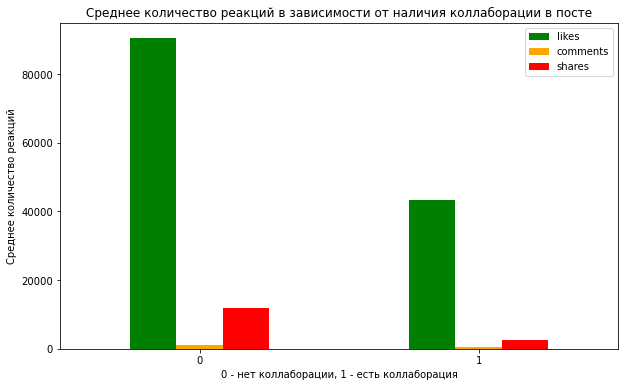

In [23]:
# визуализируем результаты
colors = ['green', 'orange', 'red']
is_collab_mean.plot(kind='bar',
                title='Среднее количество реакций в зависимости от наличия коллаборации в посте',
                xlabel='0 - нет коллаборации, 1 - есть коллаборация',
                ylabel='Среднее количество реакций',
                rot=0,
                color=colors,          
                figsize=(10, 6))

plt.show()

График наглядно демонстирует, какое большое влияние оказывает наличие совместной публикации с другим автором. 
Посты, выпущенные БЕЗ совместного авторства, получают в среднем наполовину больше реакций (например, 90390 лайков против 43229).

<b>Анализ влияния серии фотографий в посте</b>

In [24]:
# исследуем влияние серии фотографий в посте на среднее количество реакций
is_series_mean = insta_data.groupby('is_series').agg({'likes':'mean','comments':'mean','shares':'mean'}).round(0).astype(int)
is_series_mean

,likes,comments,shares
is_series,,,
0,77544,1045,9681
1,35832,314,749


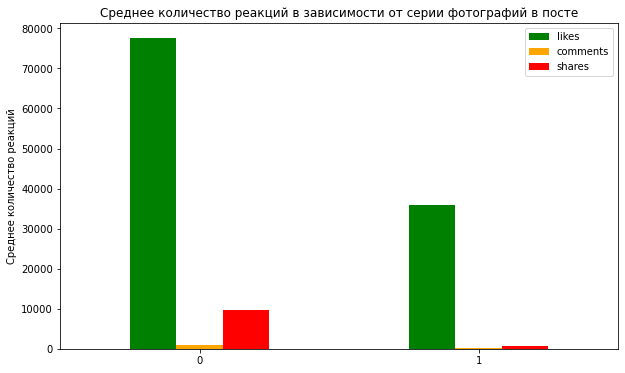

In [25]:
# визуализируем результаты
is_series_mean.plot(kind='bar',
                title='Среднее количество реакций в зависимости от серии фотографий в посте',
                xlabel='',
                ylabel='Среднее количество реакций',
                rot=0,
                color=colors,          
                figsize=(10, 6))

plt.show()

В среднем гораздо больше реакций получают посты, где нет "серии" фотографий. Так, посты БЕЗ серии в среднем получают 77544 лайков и 1045 комментариев против 35832 лайков и 314 комментариев соответственно.

## Итоговые выводы

Анализ влияния различных факторов на поведение подписчиков позволил выявить следующие закономерности:

- Больше всего реакций от подписчиков получают посты, опубликованные в понедельник и четверг. Меньше всего реакций ставят по средам.

- Идеальная разница между публикациями - 1-2 дня. Именно такие посты имеют существенно больше реакций. Это может быть связано с тем, что люди психологически не готовы воспринимать контент от одной персоны чаще, чем 1 раз в день, и даже испытывать раздражение от этого. Пауза в 1-2 дня стимулирует больший интерес к личности.

- Аудитории нравится смотреть выдержки из интервью Ирины, слушать ее откровения, так как она выглядит очень думающим и честным человеком и поднимает острые темы. Также хорошо "заходит" тема семьи и лайф-контент. Подписчиков подкупает, когда медиаперсона открыто рассказывает о своей жизни за пределами камер. Меньше всего реакций имеют посты с анонсами киноработ Ирины. Вероятно, такие посты считываются как рекламные.

- Посты без коллаборации с другим автором получают больше реакций. "Совместный пост" может психологически считываться подписчиками как реклама или попытка продвинуть какой-то бренд.

- Посты, где нет "серии" фотографий, имеют значительно больше реакций. После того, как пользователь пролистал серию, он может забыть поставить реакцию, возможно ему сложнее вернуться к началу и оценит пост. Вероятно, когда фотография одна, порыв подписчика оценить ее гораздо сильнее.